# 보충 실험 2 — GAN으로 연체자 데이터를 만들어 늘리면?

교수님 논문 NOTE(Han et al., Sci Rep 2024)는 연체자(소수 클래스)가 적은 문제를 **GAN으로 연체자 데이터를 생성해 늘리는 방식(오버샘플링)**으로 다룬다.
같은 생각을 이 데이터에 적용해 본다. (NOTE는 오토인코더 + 조건부 Wasserstein GAN을 쓰고, 여기서는 Lecture 7의 기본 GAN 구조로 단순화했다.)

**GAN:** 생성자(가짜 연체자를 만듦)와 판별자(진짜/가짜를 가림)가 서로 경쟁하며 학습한다 (Lecture 7).

비교 (같은 층화 10-fold, 분류기는 Lab 5 최종 모델과 같은 정리 + RF):
1. 늘리지 않음 (Lab 5 기준)
2. 무작위 복제: 연체자를 그대로 복사해 정상 수와 맞춤
3. SMOTE: 연체자 두 명 사이의 점을 만들어 늘림 (문헌에서 가장 흔한 방법)
4. **GAN**: 생성자가 만든 가짜 연체자로 늘림

**누수 주의:** 늘리기는 반드시 **각 fold의 학습 데이터 안에서만** 한다. 시험 데이터는 진짜 고객만 남긴다.
마지막에 '나누기 전에 전체를 늘리면' 점수가 어떻게 부풀려지는지도 확인한다.

In [1]:
import os, time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy
from pandas import read_csv, DataFrame
from matplotlib import pyplot, font_manager
import glob
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
import keras
from keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score

for p in glob.glob(os.path.expandvars(r'%LOCALAPPDATA%\Microsoft\Windows\Fonts\Pretendard-*.ttf')):
    from matplotlib import font_manager as fm; fm.fontManager.addfont(p)
pyplot.rcParams['font.family'] = 'Pretendard'
pyplot.rcParams['axes.unicode_minus'] = False
BLUE, RED, GRAY, VIOLET, INK = '#3182F6', '#F04452', '#B0B8C1', '#7C5CFF', '#191F28'

SMOKE = os.environ.get('SMOKE') == '1'
seed = 7
names = ['target', 'revol', 'age', 'late30', 'debt', 'income', 'depend', 'defaulted', 'loans']
features = names[1:]
dataframe = read_csv('../data/givemesomecredit.csv', names=names, header=0)
X = dataframe.values[:, 1:9].astype(float)
Y = dataframe.values[:, 0].astype(int)
if SMOKE:
    X, _, Y, _ = train_test_split(X, Y, train_size=8000, random_state=seed, stratify=Y)
GAN_STEPS = 200 if SMOKE else 3000

def clean(A):
    A = A.copy()
    code = numpy.isin(A[:, 2], [96, 98]).astype(float)
    fill = numpy.isin(A[:, 4], [6638, 6746]).astype(float)
    A[code == 1, 2] = 0
    return numpy.column_stack([A, code, fill])

Xc = clean(X)                                   # 10열: 8개 변수 + 코드 표시 + 소득 대체값 표시
COLS = features + ['code', 'fill']
LOG = [0, 2, 3, 4]                              # 치우친 열 (revol, late30, debt, income)
BIN = [6, 7, 8, 9]                              # 0/1 열 (defaulted, loans, code, fill)
INT = [1, 2, 5]                                 # 정수 열 (age, late30, depend)
rf = lambda: RandomForestClassifier(n_estimators=100, max_features=3, min_samples_leaf=176, random_state=seed, n_jobs=-1)
print(Xc.shape, '연체자', Y.sum(), '· SMOKE' if SMOKE else '')

(150000, 10) 연체자 10026 


## 늘리는 방법 세 가지 (모두 학습 데이터의 연체자만 보고 만든다)

In [2]:
def to_space(A):                                # 생성용 공간: 로그 후 표준화
    B = A.copy(); B[:, LOG] = numpy.log1p(B[:, LOG]); return B

def from_space(B, ref):
    """생성한 값을 원래 단위로 되돌리고, 0/1·정수 열은 반올림, 범위는 진짜 연체자 범위로 자른다."""
    A = B.copy(); A[:, LOG] = numpy.expm1(A[:, LOG])
    A[:, BIN] = (A[:, BIN] > 0.5).astype(float)
    A[:, INT] = numpy.round(A[:, INT])
    return numpy.clip(A, ref.min(axis=0), ref.max(axis=0))

def random_copy(Xpos, n, rng):
    return Xpos[rng.randint(0, len(Xpos), n)]

def smote(Xpos, n, rng, k=5):
    S = StandardScaler().fit(to_space(Xpos)); Z = S.transform(to_space(Xpos))
    nn = NearestNeighbors(n_neighbors=k + 1).fit(Z)
    _, idx = nn.kneighbors(Z)
    a = rng.randint(0, len(Z), n); b = idx[a, rng.randint(1, k + 1, n)]
    new = Z[a] + rng.rand(n, 1) * (Z[b] - Z[a])
    return from_space(S.inverse_transform(new), Xpos)

def train_gan(Xpos, steps=GAN_STEPS, batch=256, zdim=16):
    """기본 GAN (Lecture 7): 생성자 16 → 64 → 64 → 10, 판별자 10 → 64 → 64 → 1"""
    S = StandardScaler().fit(to_space(Xpos)); Z = S.transform(to_space(Xpos)).astype('float32')
    d = Z.shape[1]
    G = keras.Sequential([layers.Input((zdim,)), layers.Dense(64, activation='relu'), layers.Dense(64, activation='relu'), layers.Dense(d)])
    D = keras.Sequential([layers.Input((d,)), layers.Dense(64), layers.LeakyReLU(0.2), layers.Dense(64), layers.LeakyReLU(0.2), layers.Dense(1)])
    g_opt, d_opt = keras.optimizers.Adam(2e-4, beta_1=0.5), keras.optimizers.Adam(2e-4, beta_1=0.5)
    bce = keras.losses.BinaryCrossentropy(from_logits=True)

    @tf.function
    def step(real):
        z = tf.random.normal((tf.shape(real)[0], zdim))
        with tf.GradientTape() as gt, tf.GradientTape() as dt:
            fake = G(z, training=True)
            r, f = D(real, training=True), D(fake, training=True)
            d_loss = bce(tf.ones_like(r) * 0.9, r) + bce(tf.zeros_like(f), f)     # 진짜 라벨 0.9 (label smoothing)
            g_loss = bce(tf.ones_like(f), f)                                        # 판별자를 속이도록
        d_opt.apply_gradients(zip(dt.gradient(d_loss, D.trainable_variables), D.trainable_variables))
        g_opt.apply_gradients(zip(gt.gradient(g_loss, G.trainable_variables), G.trainable_variables))
        return d_loss, g_loss

    ds = tf.data.Dataset.from_tensor_slices(Z).shuffle(len(Z), seed=seed).repeat().batch(batch).take(steps)
    hist = [step(b) for b in ds]
    def sample(n):
        return from_space(S.inverse_transform(G(tf.random.normal((n, zdim)), training=False).numpy()), Xpos)
    return sample, numpy.array([[float(a), float(b)] for a, b in hist])

## 1) GAN이 만든 연체자는 진짜와 비슷한가? (첫 fold의 학습 데이터로 확인)

In [3]:
kfold = StratifiedKFold(n_splits=(3 if SMOKE else 10), shuffle=True, random_state=seed)
folds = list(kfold.split(Xc, Y))
tr, te = folds[0]
Xpos = Xc[tr][Y[tr] == 1]
keras.utils.set_random_seed(seed)
t0 = time.time(); sample, hist = train_gan(Xpos); gan_sec = time.time() - t0
fake = sample(len(Xpos))
comp = DataFrame({'진짜 평균': Xpos.mean(0), 'GAN 평균': fake.mean(0), '진짜 중앙값': numpy.median(Xpos, 0), 'GAN 중앙값': numpy.median(fake, 0)}, index=COLS)
print(f'GAN 학습 {gan_sec:.0f}초 ({GAN_STEPS}번 갱신, 연체자 {len(Xpos):,}명)')
print(comp.round(3).to_string())

GAN 학습 6초 (3000번 갱신, 연체자 9,023명)
              진짜 평균    GAN 평균    진짜 중앙값   GAN 중앙값
revol         4.065     0.388     0.838     0.372
age          45.971    42.578    46.000    42.000
late30        0.956     1.254     0.000     1.000
debt        296.527  1213.053     0.430     0.907
income     5790.086  4361.644  5250.000  3835.997
depend        0.929     1.036     0.000     1.000
defaulted     0.673     0.740     1.000     1.000
loans         0.656     0.703     1.000     1.000
code          0.014     0.000     0.000     0.000
fill          0.167     0.118     0.000     0.000


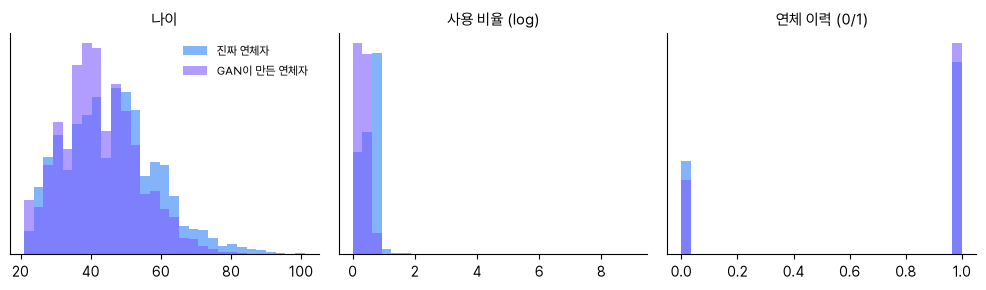

In [4]:
fig, axes = pyplot.subplots(1, 3, figsize=(10, 3.0))
for ax, (j, lab) in zip(axes, [(1, '나이'), (0, '사용 비율 (log)'), (6, '연체 이력 (0/1)')]):
    a, b = Xpos[:, j], fake[:, j]
    if j == 0: a, b = numpy.log1p(a), numpy.log1p(b)
    bins = numpy.linspace(min(a.min(), b.min()), max(a.max(), b.max()), 30)
    ax.hist(a, bins=bins, alpha=0.6, color=BLUE, label='진짜 연체자', density=True)
    ax.hist(b, bins=bins, alpha=0.6, color=VIOLET, label='GAN이 만든 연체자', density=True)
    ax.set_title(lab, fontsize=11); ax.spines[['top', 'right']].set_visible(False); ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8.5)
pyplot.tight_layout(); pyplot.savefig('../figures/lab8_gan_samples.png', dpi=200); pyplot.show()

## 2) 같은 층화 10-fold에서 네 가지 비교 (늘리기는 각 fold 학습 데이터 안에서만)

In [5]:
rows, secs = [], {}
methods = ['늘리지 않음', '무작위 복제', 'SMOTE', 'GAN']
for k, (tr, te) in enumerate(folds):
    rng = numpy.random.RandomState(seed + k)
    Xtr, ytr = Xc[tr], Y[tr]
    Xpos = Xtr[ytr == 1]; n_new = int((ytr == 0).sum() - (ytr == 1).sum())   # 연체자 = 정상 수가 되도록
    for name in methods:
        t0 = time.time()
        if name == '늘리지 않음':
            Xa, ya = Xtr, ytr
        else:
            if name == '무작위 복제': new = random_copy(Xpos, n_new, rng)
            elif name == 'SMOTE': new = smote(Xpos, n_new, rng)
            else:
                keras.utils.set_random_seed(seed + k); sample, _ = train_gan(Xpos); new = sample(n_new)
            Xa, ya = numpy.vstack([Xtr, new]), numpy.concatenate([ytr, numpy.ones(n_new, int)])
        m = rf().fit(Xa, ya)
        rows.append((name, k, roc_auc_score(Y[te], m.predict_proba(Xc[te])[:, 1])))   # 시험은 진짜 고객만
        secs[name] = secs.get(name, 0) + time.time() - t0
    print(f'fold {k + 1}: ' + ' · '.join(f'{n} {a:.4f}' for n, kk, a in rows if kk == k), flush=True)
df = DataFrame(rows, columns=['방법', 'fold', 'AUC']).pivot(index='fold', columns='방법', values='AUC')[methods]
base = df['늘리지 않음']
summary = DataFrame({'AUC': df.mean(), '흔들림': df.std(ddof=0), '기준 대비': df.sub(base, axis=0).mean(),
                     '이긴 조각 수': (df.sub(base, axis=0) > 0).sum(), '초/조각': {k: v / len(folds) for k, v in secs.items()}})
print(summary.round(4).to_string())
df.to_csv('08_gan_fold_scores.csv' if not SMOKE else '08_smoke.csv')

fold 1: 늘리지 않음 0.8630 · 무작위 복제 0.8621 · SMOTE 0.8576 · GAN 0.8018


fold 2: 늘리지 않음 0.8506 · 무작위 복제 0.8515 · SMOTE 0.8490 · GAN 0.8208


fold 3: 늘리지 않음 0.8709 · 무작위 복제 0.8700 · SMOTE 0.8654 · GAN 0.7993


fold 4: 늘리지 않음 0.8453 · 무작위 복제 0.8452 · SMOTE 0.8417 · GAN 0.8246


fold 5: 늘리지 않음 0.8603 · 무작위 복제 0.8598 · SMOTE 0.8565 · GAN 0.8166


fold 6: 늘리지 않음 0.8512 · 무작위 복제 0.8509 · SMOTE 0.8517 · GAN 0.8220


fold 7: 늘리지 않음 0.8556 · 무작위 복제 0.8556 · SMOTE 0.8503 · GAN 0.8194


fold 8: 늘리지 않음 0.8515 · 무작위 복제 0.8500 · SMOTE 0.8483 · GAN 0.8172


fold 9: 늘리지 않음 0.8529 · 무작위 복제 0.8531 · SMOTE 0.8489 · GAN 0.8244


fold 10: 늘리지 않음 0.8547 · 무작위 복제 0.8542 · SMOTE 0.8495 · GAN 0.8263


           AUC     흔들림   기준 대비  이긴 조각 수     초/조각
늘리지 않음  0.8556  0.0070  0.0000        0   4.8792
무작위 복제  0.8552  0.0067 -0.0004        3   8.5592
SMOTE   0.8519  0.0061 -0.0037        1  10.7068
GAN     0.8172  0.0089 -0.0384        0  17.9239


## 3) 잘못된 방식: 나누기 전에 전체 데이터를 GAN으로 늘리면?

In [6]:
keras.utils.set_random_seed(seed)
Xpos_all = Xc[Y == 1]; n_new = int((Y == 0).sum() - (Y == 1).sum())
sample_all, _ = train_gan(Xpos_all); new = sample_all(n_new)
Xbig, ybig = numpy.vstack([Xc, new]), numpy.concatenate([Y, numpy.ones(n_new, int)])
wrong = []
for tr, te in StratifiedKFold(n_splits=(3 if SMOKE else 10), shuffle=True, random_state=seed).split(Xbig, ybig):
    m = rf().fit(Xbig[tr], ybig[tr]); wrong.append(roc_auc_score(ybig[te], m.predict_proba(Xbig[te])[:, 1]))
print(f'전체를 먼저 늘린 뒤 10-fold (시험에 가짜 연체자 포함): AUC {numpy.mean(wrong):.4f} (± {numpy.std(wrong):.4f})')
print(f'각 fold 안에서만 늘리고 진짜 고객으로 시험:            AUC {summary.loc["GAN", "AUC"]:.4f}')

전체를 먼저 늘린 뒤 10-fold (시험에 가짜 연체자 포함): AUC 0.9501 (± 0.0013)
각 fold 안에서만 늘리고 진짜 고객으로 시험:            AUC 0.8172


시험 데이터에 GAN이 만든 가짜 연체자가 섞이면, 모델은 '진짜 고객 속의 연체자'가 아니라 '가짜 연체자의 특징'을 구별하게 되어 점수가 부풀려진다.
그래서 늘리기는 반드시 학습 데이터 안에서만 하고, 시험은 진짜 고객으로만 해야 한다.

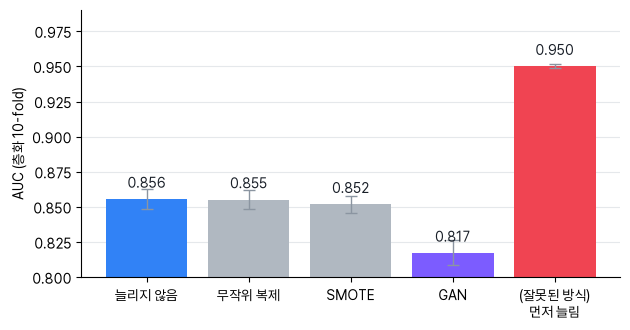

In [7]:
fig, ax = pyplot.subplots(figsize=(6.4, 3.4))
labels = methods + ['(잘못된 방식)\n먼저 늘림']
vals = [summary.loc[m, 'AUC'] for m in methods] + [numpy.mean(wrong)]
errs = [summary.loc[m, '흔들림'] for m in methods] + [numpy.std(wrong)]
ax.bar(labels, vals, yerr=errs, color=[BLUE, GRAY, GRAY, VIOLET, RED], capsize=4, error_kw={'ecolor': '#8B95A1', 'lw': 1})
for i, v in enumerate(vals):
    ax.text(i, v + 0.008, f'{v:.3f}', ha='center', fontsize=10, color=INK)
ax.set_ylim(0.80, min(1.0, max(vals) + 0.04)); ax.set_ylabel('AUC (층화 10-fold)')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#E5E8EB'); ax.set_axisbelow(True)
pyplot.tight_layout(); pyplot.savefig('../figures/lab8_gan_compare.png', dpi=200); pyplot.show()

## 정리
- **어떤 방식으로 늘려도 좋아지지 않았다.** 늘리지 않음 0.8556 · 무작위 복제 0.8552 · SMOTE 0.8519 · **GAN 0.8172 (-0.038)**.
- GAN이 만든 연체자는 나이·연체 이력 분포는 비슷했지만 부채 비율·사용 비율이 진짜와 많이 달랐다. 분류기가 '진짜 연체자'가 아닌 '가짜 연체자의 특징'까지 배워 점수가 떨어진 것으로 보인다.
  (NOTE 논문의 오토인코더 + 조건부 WGAN이 아닌 기본 GAN이라 생성 품질에 한계가 있다.)
- 문헌(Ichim & Issa 2025)도 데이터를 늘리는 방법보다 학습할 때 가중치를 주는 방법이 낫다고 보고했다. 이 데이터에서도 Lab 4의 연체자 가중치·잎 크기 조절이 더 효과적이었다.
- **평가 방식이 결과를 바꾼다.** 같은 GAN도 나누기 전에 전체를 늘리면 시험에 가짜 연체자가 섞여 **0.950**이 나온다. 진짜 고객으로만 시험하면 0.817이다. 늘리기는 반드시 학습 데이터 안에서만 해야 한다.